# Figure 6: melanoma spatial Hi-C + RNA

From the Higashi chromatin layers and the RNA matrix to every Saturn panel of Fig. 6: A/B matrix, targets, the two
Saturn fits, chromatin-gene tables, and the figure.

**What is not rerun:** Higashi and Fast-Higashi. Their outputs (`scCompartment.hdf5`, `scTAD.hdf5`, `read_count_all.npy`)
are declared as inputs. The recovered training is in section 0, switched off by default.

**Env:** `spatialmultivelo` (this kernel). Section 0 alone needs `higashi` and a GPU.
**Time:** about 55 min on a shared machine: fits 9 and 6 min on 8 CPU threads (load 50-70); series and Granger steps about 35 min; figure about 1 min.

**Panels dropped:** none; Fig. 6 has no baseline panels. The exploratory Spearman, orderings, reversal and direction
builders in `fig6/` were not used in the final figure and are left out.

In [1]:
import os, sys; sys.path.insert(0, ".")
from pathlib import Path
import numpy as np
import nbutil as nb
nb.init("fig6")
STEPS = Path(nb.__file__).resolve().parent / "steps"; ENV = dict(SATURN_ROOT=str(nb.ROOT))
FH = "mel_hic_fh_dr50_51"; DS = "mel_hic_abins_dr50_51_rnadr"
GF, G = f"results/real_saturn/{FH}_insulation_granger", f"results/real_saturn/{DS}_insulation_granger"


def compare_npz(rel, keys):
    """Published vs this workspace for arrays of one .npz under results/real_saturn."""
    if nb.PUB is None: return
    a = np.load(nb.RES / rel, allow_pickle=True); b = np.load(nb.PUB / "Hole/gaston_mix_mm/results/real_saturn" / rel, allow_pickle=True)
    for k in keys:
        x, y = a[k], b[k]
        same = x.shape == y.shape and (x == y).all() if x.dtype.kind in "USO" else None
        print(f"{rel} {k} {x.shape}:", ("identical" if same else "DIFFERS") if same is not None else f"max|diff| {np.abs(x - y).max():.3g}")

ok      SpHIC117/RNA/raw/barcodes.tsv.gz  [raw: SpHIC117 melanoma 10x RNA matrix (full 62,700 genes)]
ok      SpHIC117/RNA/raw/features.tsv.gz  [raw: SpHIC117 melanoma 10x RNA matrix]
ok      SpHIC117/RNA/raw/matrix.mtx.gz  [raw: SpHIC117 melanoma 10x RNA matrix]
ok      protein_coding_genes_human.bed  [reference: protein-coding gene coordinates, hg38, lab file with no recovered builder]
ok      HIC_repo/Melanoma/annotated_adata.h5ad  [lab intermediate, no single recovered producer: spots, chip coordinates, X_fh, Starfysh proportions, CellCharter labels (SpHIC117/melanoma.ipynb and later notebooks)]
ok      Hole/gaston_mix_mm/results/real_saturn/targets_mel_hic_fh_dr50_51.npz  [lab intermediate, published draw: only Y_RNA is used. GLM-PCA is unseeded, so this draw has no reproducible producer (mel_hic_prep.py gives a different one)]
ok      SpHIC117/HIC/higashi/tmp/scCompartment.hdf5  [Higashi output NOT rerun (recovered training in steps/fig6_higashi.py; scCompartment.py command line 

## 0. Higashi (switched off, not rerun)
Raw per-spot contacts -> Fast-Higashi and Higashi imputation at 500 kb and 100 kb, then Higashi's `scCompartment.py` and
`scTAD.py`. Recovered from `SpHIC117/prep_dataset.py`, `imputate.py`, `imputate_100.py`. The command lines of the last two
scripts and the 100 kb `process_data` call were not found. Takes days on GPU and more than 600 GB of temporary files.

In [2]:
RUN_HIGASHI = False
if RUN_HIGASHI:
    for st in ("500kb_prep", "500kb_train", "100kb_train"):
        nb.step(f"higashi_{st}", f"python {STEPS}/fig6_higashi.py {st}", env="higashi", extra_env=ENV)
    raise SystemExit("Now run Higashi's scCompartment.py and scTAD.py: their flags were not recovered")
print("Higashi not rerun: its outputs are inputs of this notebook")

Higashi not rerun: its outputs are inputs of this notebook


## 1. A/B compartment matrix
Per-spot A/B z-scores, 5,359 bins, 500 kb. Recovered from `SpHIC117/melanoma.ipynb` cells 40 and 39.

In [3]:
AB = nb.ROOT / "SpHIC117/abcompartment_matrix.csv"
nb.step("ab_matrix", f"python {STEPS}/fig6_ab_matrix.py", [str(AB)], extra_env=ENV)
if nb.PUB:
    import filecmp
    print("abcompartment_matrix.csv byte-identical to the lab file:", filecmp.cmp(AB, nb.PUB / "SpHIC117/abcompartment_matrix.csv", shallow=False))

[skip] ab_matrix: outputs exist


abcompartment_matrix.csv byte-identical to the lab file: True


## 2. Scaffold fit on the Fast-Higashi embedding
Chip rows 50-51 (a DBiT channel dip) are dropped: 6,108 spots. RNA GLM-PCA on the full matrix, Hi-C = 10 PCs of `X_fh`.
This older fit is required only as a scaffold: `mel_hic_insulation_granger.py` reads its spot order and writes
`cache_series.npz` (per-spot A/B, insulation and gene score for 2,558 bins, none of which depend on the axes), and the
final target starts from its npz. Published settings: `SAT_THREADS=8`, OMP unset, CPU, seed 42.
The third step runs the script's default mode, as published; its tables are not used by the figure.

**The RNA GLM-PCs cannot be regenerated.** `glmpca` starts from `np.random.randn` and no seed is set, so each prep gives a
different draw. The prep is run for real, then its `Y_RNA` is replaced by the published draw, read from the declared input
`targets_mel_hic_fh_dr50_51.npz`. The fresh draw is kept in `glmpc_fresh_draw_mel_hic_fh_dr50_51.npz`. Control run with a fresh draw, final fit (2026-11-06): rho_HiC |r| 0.986 with published, rho_RNA |r| only 0.289, rho_RNA~rho_HiC 0.43 vs 0.755 published. So rho_RNA depends on the draw, and the published Fig. 6 depends on this input.

In [4]:
T, DRAW = nb.RES / f"targets_{FH}.npz", nb.RES / f"glmpc_published_{FH}.npz"
if not DRAW.exists():                                        # the declared input: keep its Y_RNA, then drop the link so the prep writes here
    z = np.load(T, allow_pickle=True); np.savez_compressed(DRAW, Y_RNA=z["Y_RNA"], barcodes=z["barcodes"]); T.unlink()
nb.step("prep_fh", "python scripts/mel_hic_prep.py --drop_rows 50 51", [T])
nb.step("restore_glmpc", f"python {STEPS}/fig6_restore_glmpc.py {nb.RES} {DRAW}", [nb.RES / f"glmpc_fresh_draw_{FH}.npz"])
f, p = np.load(nb.RES / f"glmpc_fresh_draw_{FH}.npz")["Y_RNA"].astype(float), np.load(DRAW)["Y_RNA"].astype(float)
print("canonical correlations, fresh vs published GLM-PCs:", np.linalg.svd(np.linalg.qr(f - f.mean(0))[0].T @ np.linalg.qr(p - p.mean(0))[0])[1].round(3))
compare_npz(f"targets_{FH}.npz", ["barcodes", "coords", "Y_RNA", "Y_HiC", "depth_RNA"])
nb.step("fit_fh", f"python scripts/run_real2.py --dataset {FH} --seeds 1 --seed0 42", [f"results/real_saturn/{FH}/axes.csv"], threads=8)
nb.compare_axes(FH)
nb.step("series_fh", f"python scripts/mel_hic_insulation_granger.py --ds {FH}", [f"{GF}/cache_series.npz", f"{GF}/spot_insulation_summary.npy"])
compare_npz(f"{FH}_insulation_granger/cache_series.npz", ["AB", "IN", "S", "names", "genes", "bc"])

[skip] prep_fh: outputs exist
[skip] restore_glmpc: outputs exist
canonical correlations, fresh vs published GLM-PCs: [0.999 0.994 0.989 0.984 0.971 0.926 0.909 0.701 0.415 0.219]
targets_mel_hic_fh_dr50_51.npz barcodes (6108,): identical
targets_mel_hic_fh_dr50_51.npz coords (6108, 2): max|diff| 0
targets_mel_hic_fh_dr50_51.npz Y_RNA (6108, 10): max|diff| 0
targets_mel_hic_fh_dr50_51.npz Y_HiC (6108, 10): max|diff| 0
targets_mel_hic_fh_dr50_51.npz depth_RNA (6108,): max|diff| 0
[skip] fit_fh: outputs exist
           dataset  axis  max_abs_diff  abs_r
mel_hic_fh_dr50_51 d_RNA           0.0    1.0
mel_hic_fh_dr50_51 d_HiC           0.0    1.0
[skip] series_fh: outputs exist


mel_hic_fh_dr50_51_insulation_granger/cache_series.npz AB (6108, 2558): max|diff| 0


mel_hic_fh_dr50_51_insulation_granger/cache_series.npz IN (6108, 2558): max|diff| 0


mel_hic_fh_dr50_51_insulation_granger/cache_series.npz S (6108, 2558): max|diff| 0
mel_hic_fh_dr50_51_insulation_granger/cache_series.npz names (2558,): identical
mel_hic_fh_dr50_51_insulation_granger/cache_series.npz genes (2558,): identical
mel_hic_fh_dr50_51_insulation_granger/cache_series.npz bc (6108,): identical


## 3. Final target and fit
Hi-C target = the chromatin layers themselves: A/B and insulation per 500 kb bin, each regressed on a cubic in log Hi-C
reads, z-scored, layers weighted equally, 10 PCs. A cubic in log RNA depth is also regressed out of the RNA GLM-PCs.
Published settings: `SAT_THREADS=8`, OMP unset, CPU, seed 42.

In [5]:
nb.step("prep_abins", "python scripts/mel_hic_abins_prep.py --rna-dr", [f"results/real_saturn/targets_{DS}.npz"])
compare_npz(f"targets_{DS}.npz", ["barcodes", "Y_RNA", "Y_HiC", "depth_HiC"])
nb.step("fit_abins", f"python scripts/run_real2.py --dataset {DS} --seeds 1 --seed0 42", [f"results/real_saturn/{DS}/axes.csv"], threads=8)
nb.compare_axes(DS)

[skip] prep_abins: outputs exist
targets_mel_hic_abins_dr50_51_rnadr.npz barcodes (6108,): identical
targets_mel_hic_abins_dr50_51_rnadr.npz Y_RNA (6108, 10): max|diff| 0
targets_mel_hic_abins_dr50_51_rnadr.npz Y_HiC (6108, 10): max|diff| 0
targets_mel_hic_abins_dr50_51_rnadr.npz depth_HiC (6108,): max|diff| 0
[skip] fit_abins: outputs exist
                    dataset  axis  max_abs_diff  abs_r
mel_hic_abins_dr50_51_rnadr d_RNA           0.0    1.0
mel_hic_abins_dr50_51_rnadr d_HiC           0.0    1.0


,dataset,axis,max_abs_diff,abs_r
0,mel_hic_abins_dr50_51_rnadr,d_RNA,0.0,1.0
1,mel_hic_abins_dr50_51_rnadr,d_HiC,0.0,1.0


## 4. Chromatin along the isodepths
`--granger-only` writes this fit's `cache_series.npz`, then a raw length sweep the figure does not read (the published run
was stopped once the cache existed). `spot_insulation_summary.npy` does not depend on the axes; as published, it is copied
from a fit with the same spots (the lab files are identical by md5). Then: rho tracking with reads partialled out, Granger
vs rho length (all spots; same spots per window), direction tests, per-bin Granger, cis consistency.

In [6]:
nb.step("series_abins", f"python scripts/mel_hic_insulation_granger.py --ds {DS} --granger-only", [f"{G}/cache_series.npz"])
compare_npz(f"{DS}_insulation_granger/cache_series.npz", ["AB", "IN", "S", "names", "genes", "bc"])
nb.step("spot_summary", f"cp {GF}/spot_insulation_summary.npy {G}/", [f"{G}/spot_insulation_summary.npy"])
nb.step("bins_partial", f"python scripts/mel_hic_bins_partial.py --ds {DS}", [f"{G}/bins_vs_rho_partial.csv"])
nb.step("granger_all_spots", f"python scripts/mel_hic_insulation_granger.py --ds {DS} --natural --deg 3 --smooth-genes 25 --granger-only", [f"{G}/granger_vs_length_natural_deg3_smooth25.csv"])
nb.step("granger_same_spots", f"python scripts/mel_hic_insulation_granger.py --ds {DS} --deg 3 --smooth-genes 25 --granger-only", [f"{G}/granger_vs_length_deg3_smooth25.csv"])
nb.step("granger_direction", f"python scripts/mel_hic_insulation_granger.py --ds {DS} --direction", [f"{G}/direction_tests.csv"])
nb.step("granger_per_bin", f"python scripts/mel_hic_granger_examples.py --ds {DS}", [f"{G}/granger_per_bin.csv", f"{G}/granger_series.npz"])
nb.step("cis_threeway", f"python scripts/mel_hic_cis_threeway.py --ds {DS}", [f"{G}/cis_threeway_pairs.csv"])
nb.step("granger_domains", "python scripts/mel_hic_granger_domains.py --repeats 200 --nsub 500", [f"{G}/granger_domains_counts.csv", f"{G}/granger_domains_summary.csv"])
for t in ("bins_vs_rho_partial", "granger_vs_length_natural_deg3_smooth25", "granger_vs_length_deg3_smooth25", "direction_tests",
          "granger_per_bin", "cis_threeway_pairs", "cis_threeway_patterns", "granger_domains_counts", "granger_domains_summary"):
    nb.compare_table(f"{DS}_insulation_granger/{t}.csv")

[skip] series_abins: outputs exist


mel_hic_abins_dr50_51_rnadr_insulation_granger/cache_series.npz AB (6108, 2558): max|diff| 0


mel_hic_abins_dr50_51_rnadr_insulation_granger/cache_series.npz IN (6108, 2558): max|diff| 0


mel_hic_abins_dr50_51_rnadr_insulation_granger/cache_series.npz S (6108, 2558): max|diff| 0
mel_hic_abins_dr50_51_rnadr_insulation_granger/cache_series.npz names (2558,): identical
mel_hic_abins_dr50_51_rnadr_insulation_granger/cache_series.npz genes (2558,): identical
mel_hic_abins_dr50_51_rnadr_insulation_granger/cache_series.npz bc (6108,): identical
[skip] spot_summary: outputs exist
[skip] bins_partial: outputs exist
[skip] granger_all_spots: outputs exist
[skip] granger_same_spots: outputs exist
[skip] granger_direction: outputs exist
[skip] granger_per_bin: outputs exist
[skip] cis_threeway: outputs exist
[skip] granger_domains: outputs exist
mel_hic_abins_dr50_51_rnadr_insulation_granger/bins_vs_rho_partial.csv: shape (10232, 5) vs (10232, 5); max numeric diff 0; MATCH
mel_hic_abins_dr50_51_rnadr_insulation_granger/granger_vs_length_natural_deg3_smooth25.csv: shape (120, 13) vs (120, 13); max numeric diff 0; MATCH
mel_hic_abins_dr50_51_rnadr_insulation_granger/granger_vs_length

## 5. Figure
`fig6_melanoma_hic.py` builds the multi-panel figure and one SVG per panel. `fig6g_granger_domains.py` and
`fig6_granger_example_lines.py` build the panels finalised as Fig. 6g and 6h. Domain K comes from the kneedle elbow on the
fit (RNA 4, Hi-C 2), not from the stale fig6 row of `k_elbow.json`.

[run ] figure: python <workspace>/Saturn/published_figures/fig6/fig6_melanoma_hic.py


[done] figure: 1.1 min


[skip] panel_g: outputs exist
[skip] panel_h: outputs exist


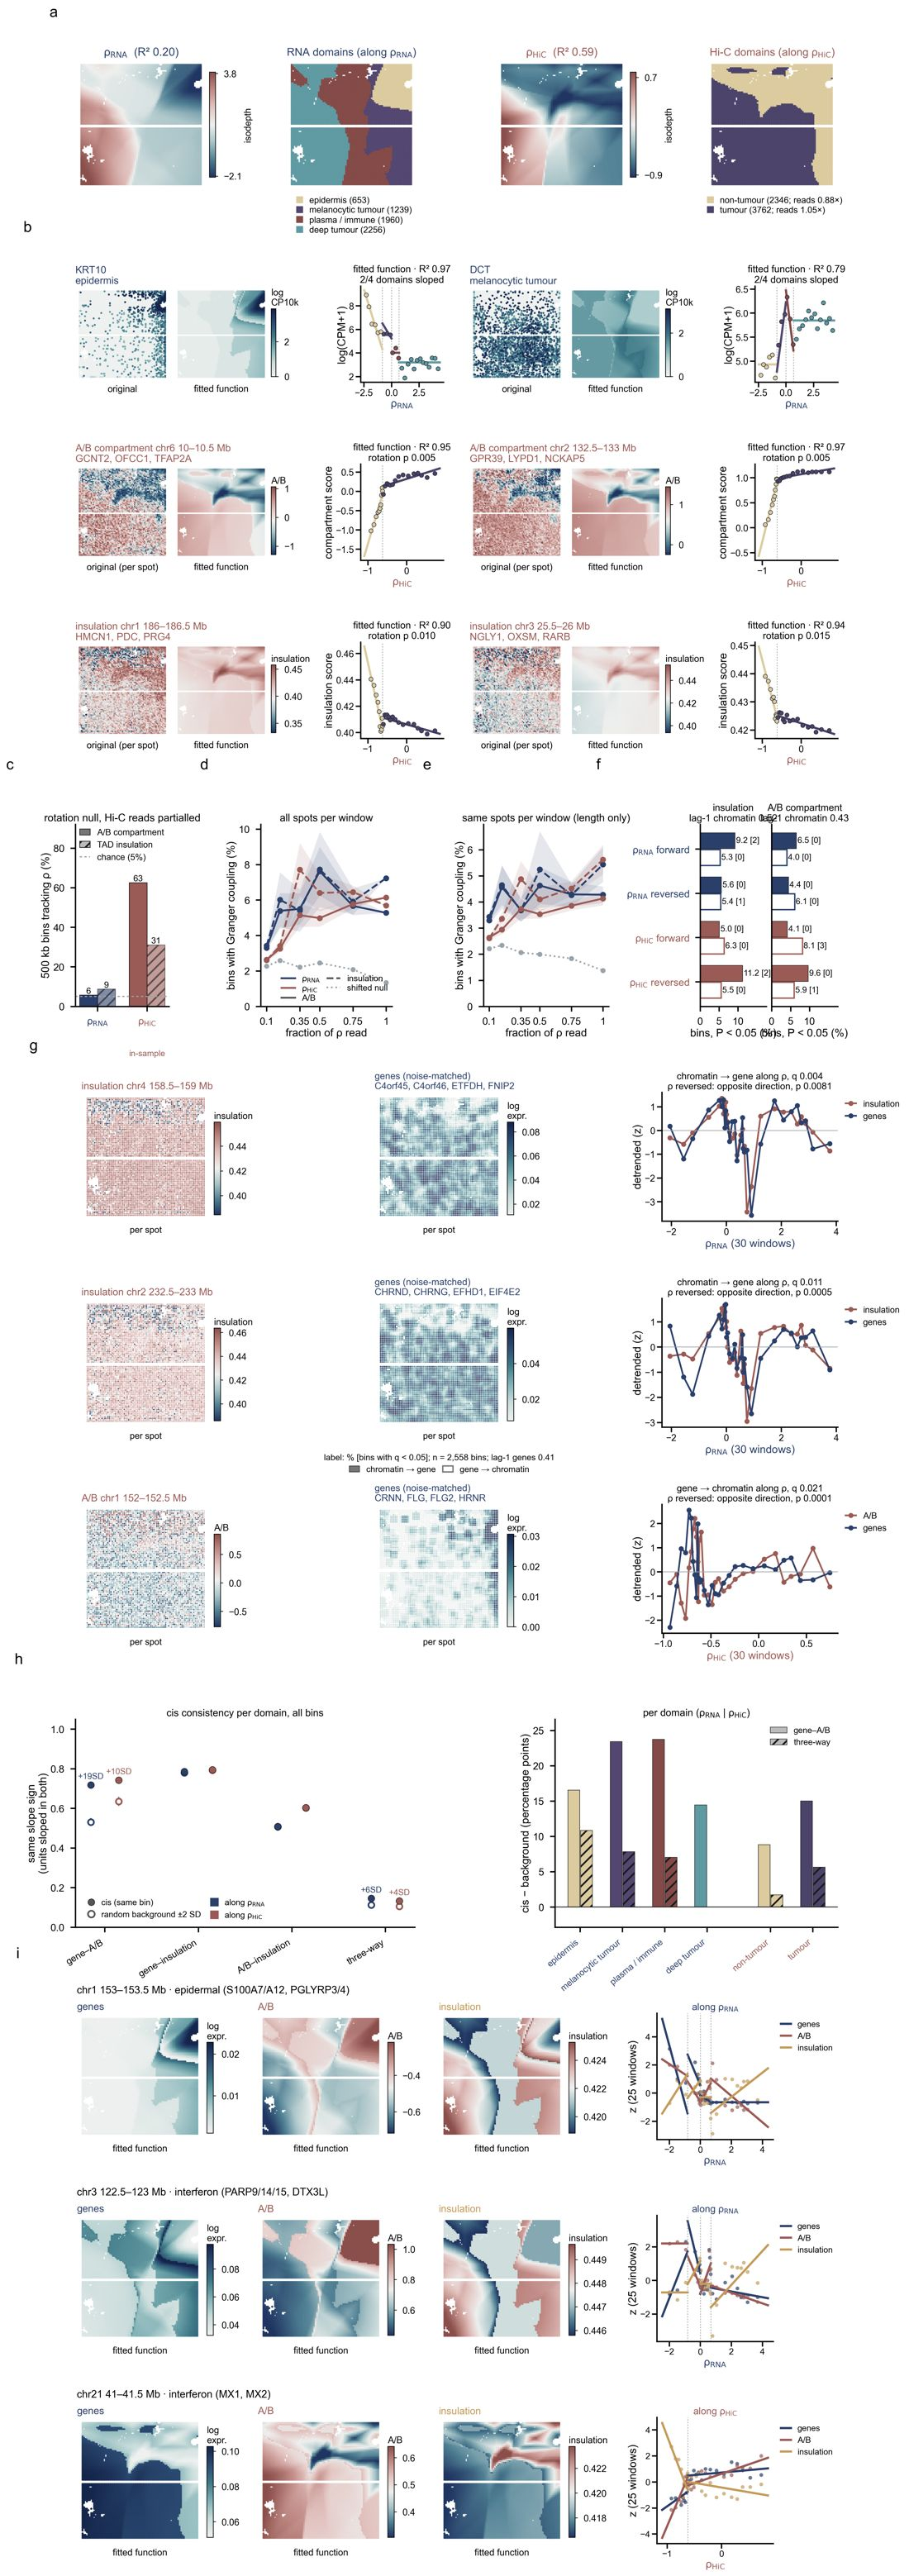

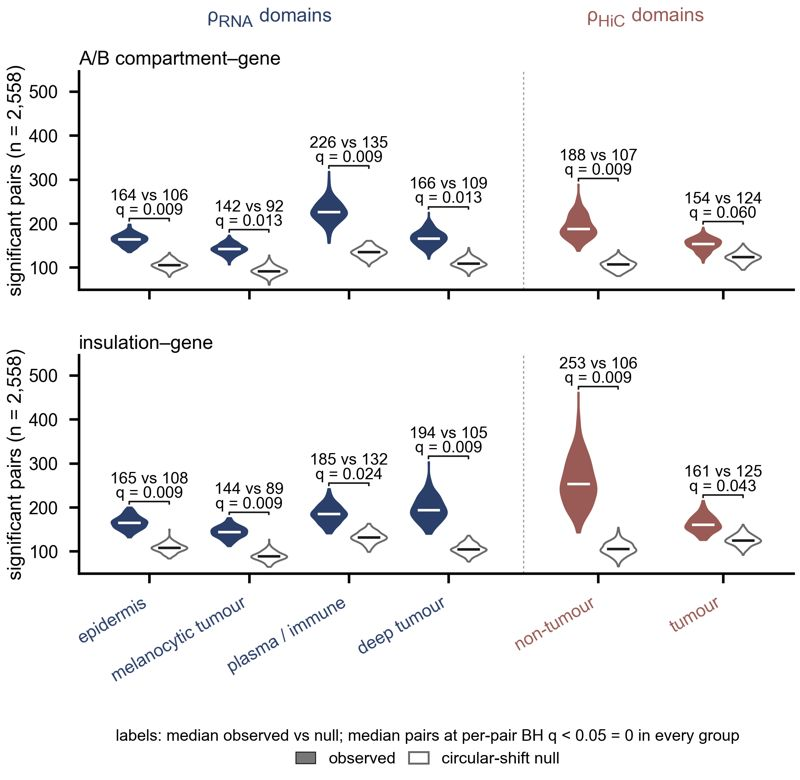

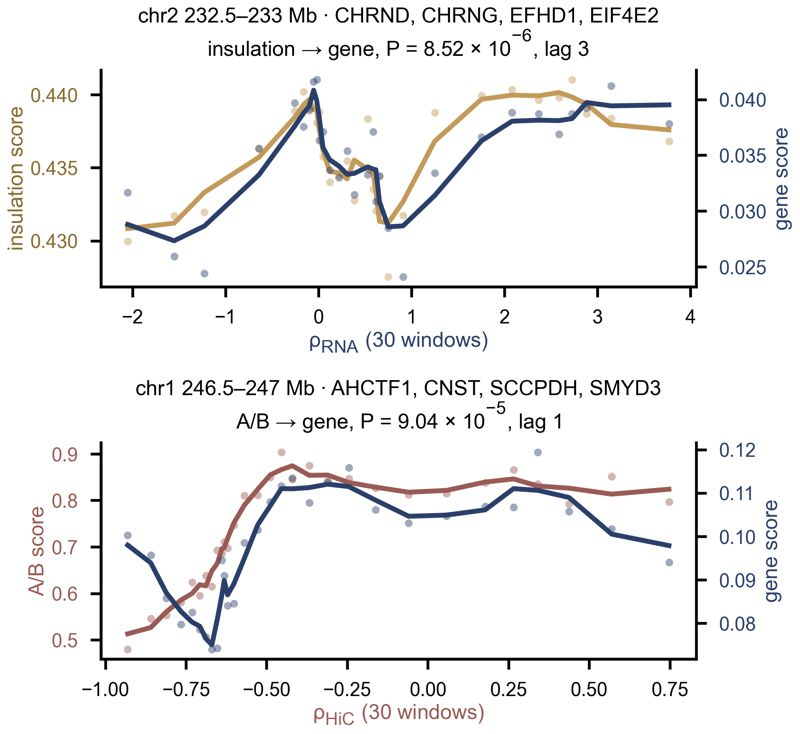

In [7]:
nb.step("figure", f"python {nb.PF}/fig6/fig6_melanoma_hic.py", [nb.PF / "fig6/fig6_melanoma_hic.png"])
nb.step("panel_g", f"python {nb.PF}/fig6/fig6g_granger_domains.py", [nb.PF / "fig6/panels/fig6g_granger_domains.png"])
nb.step("panel_h", f"python {nb.PF}/fig6/fig6_granger_example_lines.py", [nb.PF / "fig6/panels/fig6_granger_example_lines.png"])

from PIL import Image
Image.MAX_IMAGE_PIXELS = None
for f, w in (("fig6_melanoma_hic", 1100), ("panels/fig6g_granger_domains", 800), ("panels/fig6_granger_example_lines", 800)):
    im = Image.open(nb.PF / f"fig6/{f}.png"); im.thumbnail((w, 10 ** 5)); im.convert("RGB").save(nb.PF / f"fig6/{f}_preview.jpg", quality=80)
    nb.show(f"fig6/{f}_preview.jpg", width=w)